# 07 — Redundância da infraestrutura de DNS

**Pergunta:** as empresas distribuem seus servidores de nomes entre várias organizações? E as que dependem de provedores estrangeiros mantêm ao menos um provedor doméstico como alternativa?

**Métricas por empresa (IPv4)**
| Métrica | Mede |
|---|---|
| `n_ns` | nº de servidores NS distintos |
| `n_providers` | nº de **grupos controladores** distintos (`dp_as_org`) — métrica principal de redundância |
| `n_asn` | nº de ASNs distintos |
| `n_ns_apex` | nº de domínios de NS distintos (nível de nome) |
| `n_prefix` | nº de prefixos IP distintos |

**Ponto único de falha (SPOF):** a empresa tem apenas **1** provedor. A redundância por provedor é mais exigente que por NS: vários NS do mesmo provedor protegem contra falha de servidor, não contra a falha do provedor.

**Alternativa doméstica:** entre as empresas com ao menos um provedor estrangeiro (foreign-only + mixed), a fração que mantém ao menos um provedor do próprio país (mixed / (mixed + foreign-only)).

**Escopo:** apenas IPv4. Países/blocos como no notebook 06.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from IPython.display import display

from src.analysis_utils import *

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 200)
MIN_N = 30   # n mínimo de empresas para um recorte por país

v4, cp, comp = prepare()   # IPv4 -> (empresa, provedor) com peso fracionado -> 1 linha por empresa
print(f"{len(comp):,} empresas | {len(v4):,} linhas IPv4 | {cp['provider'].nunique():,} grupos de provedores")

RED_COLOR = {"1 provider": "#eb6834", "2 providers": "#6da7ec", "3+ providers": "#184f95"}
RED_ORDER = list(RED_COLOR)
comp["prov_cat"] = pd.cut(comp["n_providers"], [0, 1, 2, np.inf], labels=RED_ORDER).astype(str)
comp["rev_band"] = pd.cut(comp["rev_rank"], [0, 500, 1000, 2000, 5000, np.inf],
                          labels=["1–500", "501–1,000", "1,001–2,000", "2,001–5,000", "5,001+"]).astype(str)
BANDS = ["1–500", "501–1,000", "1,001–2,000", "2,001–5,000", "5,001+"]

10,283 empresas | 44,069 linhas IPv4 | 1,083 grupos de provedores


## 1. Quão redundantes são as empresas?

,count,mean,std,min,25%,50%,75%,max
n_ns,"10,283.00",3.13,1.46,1.00,2.00,2.00,4.00,14.00
n_providers,"10,283.00",1.20,0.57,1.00,1.00,1.00,1.00,6.00
n_asn,"10,283.00",1.33,0.96,1.00,1.00,1.00,1.00,12.00
n_ns_apex,"10,283.00",1.77,1.24,1.00,1.00,1.00,2.00,9.00
n_prefix,"10,283.00",3.62,1.88,1.00,2.00,4.00,5.00,17.00


,k,n,pct_single,lo,hi
dimension,,,,,
NS hosts,46,10283,0.45,0.34,0.60
Provider groups,8879,10283,86.35,85.67,87.00
ASNs,8291,10283,80.63,79.85,81.38
NS domains,7011,10283,68.18,67.27,69.07
IP prefixes,604,10283,5.87,5.44,6.34


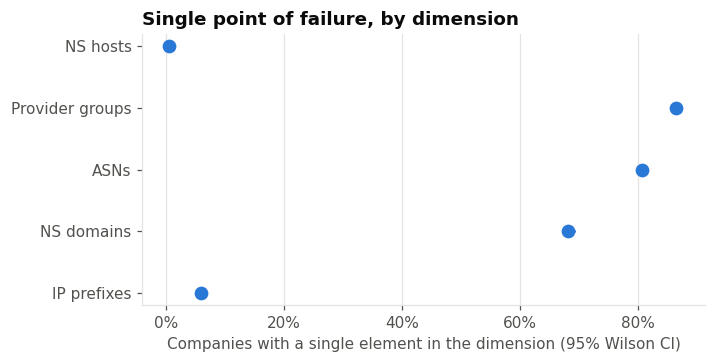

In [2]:
cols = ["n_ns", "n_providers", "n_asn", "n_ns_apex", "n_prefix"]
display(comp[cols].describe().T)

# % de empresas com apenas 1 elemento em cada dimensão (SPOF), com IC de Wilson
labels = {"n_ns": "NS hosts", "n_providers": "Provider groups", "n_asn": "ASNs",
          "n_ns_apex": "NS domains", "n_prefix": "IP prefixes"}
rows = []
for c, lab in labels.items():
    k, n = int((comp[c] == 1).sum()), len(comp)
    lo, hi = wilson_ci(k, n)
    rows.append({"dimension": lab, "k": k, "n": n, "pct_single": 100 * k / n, "lo": 100 * lo, "hi": 100 * hi})
spof = pd.DataFrame(rows).set_index("dimension")
display(spof)
save_table(spof, "red_spof_by_dimension")

fig, ax = plt.subplots(figsize=(6.6, 3.2))
ci_dots(ax, spof.index, spof["pct_single"], spof["lo"], spof["hi"], ["#2a78d6"] * len(spof))
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xlabel("Companies with a single element in the dimension (95% Wilson CI)")
ax.set_title("Single point of failure, by dimension")
save_fig(fig, "fig_red_spof_dimensions")
plt.show()

,k,n,pct,lo,hi
prov_cat,,,,,
1 provider,8879,10283,86.35,85.67,87.00
2 providers,1008,10283,9.80,9.24,10.39
3+ providers,396,10283,3.85,3.50,4.24


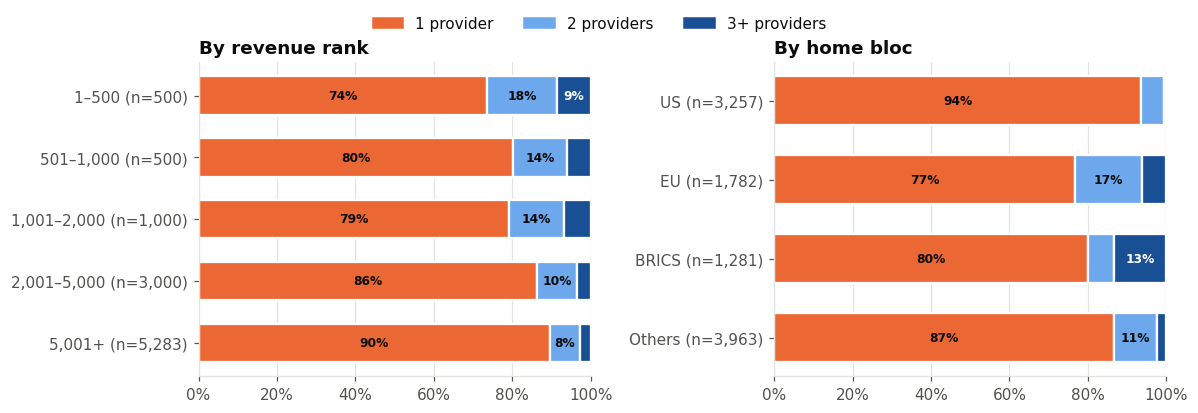

In [3]:
# distribuição do nº de provedores
dist = prop_ci_table(comp.assign(all="All"), "all", "prov_cat", RED_ORDER).set_index("prov_cat")
display(dist[["k", "n", "pct", "lo", "hi"]])
save_table(dist, "red_providers_distribution")

# por faixa de receita e por bloco
def pct_by(col, order):
    t = pd.crosstab(comp[col], comp["prov_cat"], normalize="index").mul(100)
    return t.reindex(index=order, columns=RED_ORDER).fillna(0)

pr_band = pct_by("rev_band", BANDS)
pr_bloc = pct_by("home_bloc", BLOCS)
n_band = comp["rev_band"].value_counts()
n_bloc = comp["home_bloc"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1]})
stacked_hbar(axes[0], pr_band.rename(index=lambda b: f"{b} (n={n_band[b]:,})"), RED_COLOR)
axes[0].set_title("By revenue rank")
stacked_hbar(axes[1], pr_bloc.rename(index=lambda b: f"{b} (n={n_bloc[b]:,})"), RED_COLOR)
axes[1].set_title("By home bloc")
fig.legend(handles=[Patch(color=RED_COLOR[c], label=c) for c in RED_ORDER], loc="upper center",
           ncol=3, bbox_to_anchor=(0.5, 1.05), frameon=False)
fig.tight_layout()
save_fig(fig, "fig_red_providers_dist")
plt.show()

,k,n,pct,lo,hi
home_bloc,,,,,
US,3048,3257,93.58,92.69,94.37
Others,3438,3963,86.75,85.66,87.77
BRICS,1025,1281,80.02,77.74,82.11
EU,1368,1782,76.77,74.75,78.67


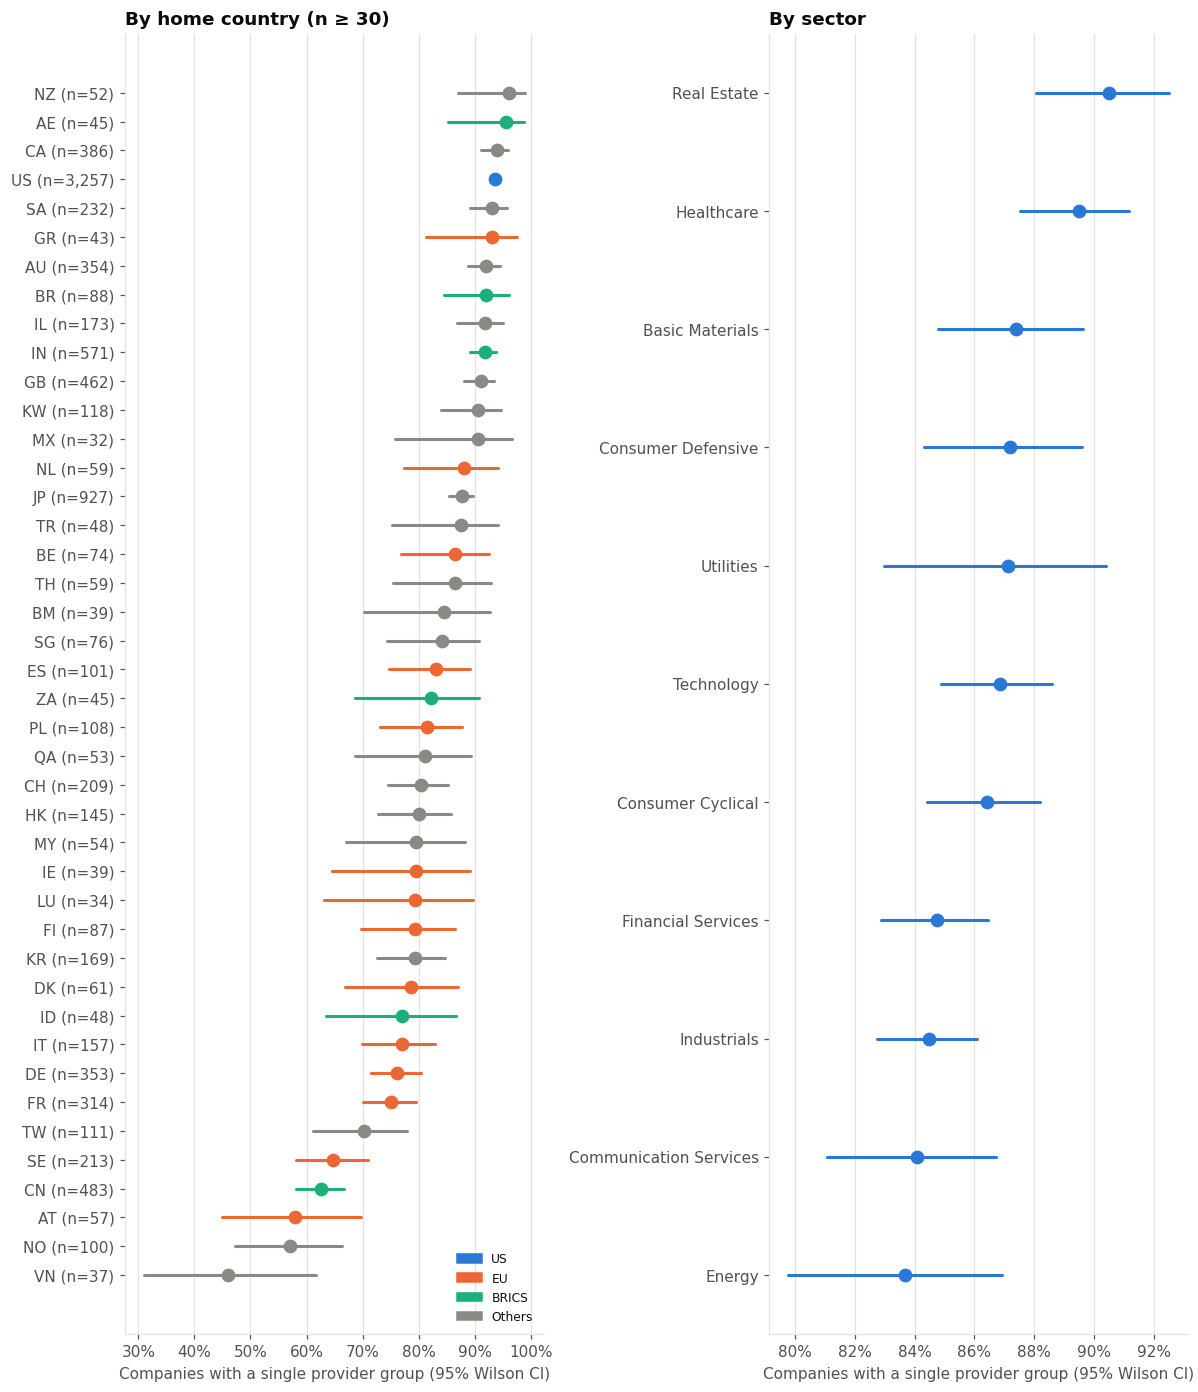

In [4]:
# SPOF por provedor: por bloco, país e setor (com IC de Wilson)
comp["single"] = np.where(comp["n_providers"] == 1, "single", "multi")

def spof_by(col, min_n=1):
    t = prop_ci_table(comp, col, "single", ["single", "multi"])
    t = t[t["single"] == "single"].set_index(col)
    return t[t["n"] >= min_n].sort_values("pct", ascending=False)

by_bloc, by_sector, by_country = spof_by("home_bloc"), spof_by("sector"), spof_by("home", MIN_N)
display(by_bloc[["k", "n", "pct", "lo", "hi"]])

fig, axes = plt.subplots(1, 2, figsize=(11, max(4.2, 0.28 * len(by_country) + 1)),
                         gridspec_kw={"width_ratios": [1, 1]})
bloc_of_country = comp.groupby("home")["home_bloc"].first()
ci_dots(axes[0], [f"{c} (n={n:,})" for c, n in zip(by_country.index, by_country["n"])],
        by_country["pct"], by_country["lo"], by_country["hi"],
        [BLOC_COLOR[bloc_of_country[c]] for c in by_country.index])
axes[0].invert_yaxis()
axes[0].set_title(f"By home country (n ≥ {MIN_N})")
axes[0].legend(handles=[Patch(color=BLOC_COLOR[b], label=b) for b in BLOCS], loc="lower right", fontsize=8)
ci_dots(axes[1], by_sector.index, by_sector["pct"], by_sector["lo"], by_sector["hi"], ["#2a78d6"] * len(by_sector))
axes[1].invert_yaxis()
axes[1].set_title("By sector")
for ax in axes:
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.set_xlabel("Companies with a single provider group (95% Wilson CI)")
fig.tight_layout()
save_fig(fig, "fig_red_single_provider_groups")
plt.show()
save_table(by_country, "red_single_provider_by_country")
save_table(by_sector, "red_single_provider_by_sector")

## 2. Redundância × dependência estrangeira

O pior caso é a empresa **foreign-only com um único provedor**: depende de uma só organização, e essa organização está fora do país.

prov_cat,1 provider,2 providers,3+ providers
dependence_type,,,
domestic-only,4060,401,173
mixed,0,351,167
foreign-only,4819,256,56


prov_cat,1 provider,2 providers,3+ providers
dependence_type,,,
domestic-only,87.61,8.65,3.73
mixed,0.00,67.76,32.24
foreign-only,93.92,4.99,1.09


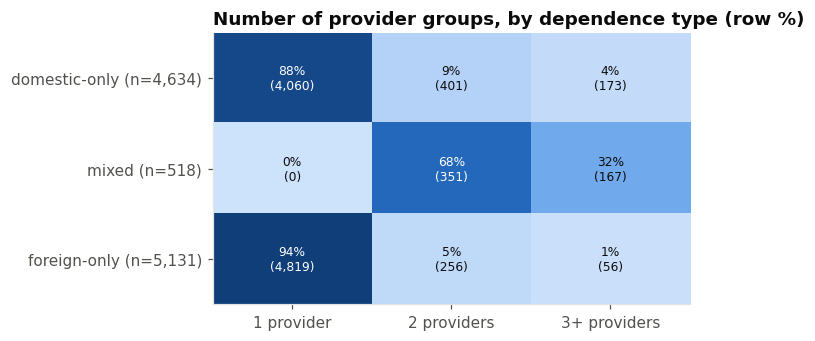

In [5]:
ct = pd.crosstab(comp["dependence_type"], comp["prov_cat"]).reindex(index=DEP_ORDER, columns=RED_ORDER)
pct_row = ct.div(ct.sum(axis=1), axis=0) * 100
display(ct)
display(pct_row)
save_table(ct, "red_dep_x_providers_counts")

fig, ax = plt.subplots(figsize=(5.6, 3.2))
im = ax.imshow(pct_row.to_numpy(), cmap=seq_cmap(), vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(3))
ax.set_xticklabels(RED_ORDER)
ax.set_yticks(range(3))
ax.set_yticklabels([f"{d} (n={ct.loc[d].sum():,})" for d in DEP_ORDER])
ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{pct_row.iat[i, j]:.0f}%\n({ct.iat[i, j]:,})", ha="center", va="center",
                fontsize=8, color="white" if pct_row.iat[i, j] > 55 else INK)
ax.set_title("Number of provider groups, by dependence type (row %)")
save_fig(fig, "fig_red_dep_x_providers")
plt.show()

Casos críticos: 4,819 de 10,283 (46.9%) | receita: 31.8%


,k,n,pct,lo,hi
home_bloc,,,,,
US,586,3257,17.99,16.71,19.35
EU,931,1782,52.24,49.92,54.56
BRICS,675,1281,52.69,49.96,55.42
Others,2627,3963,66.29,64.80,67.74


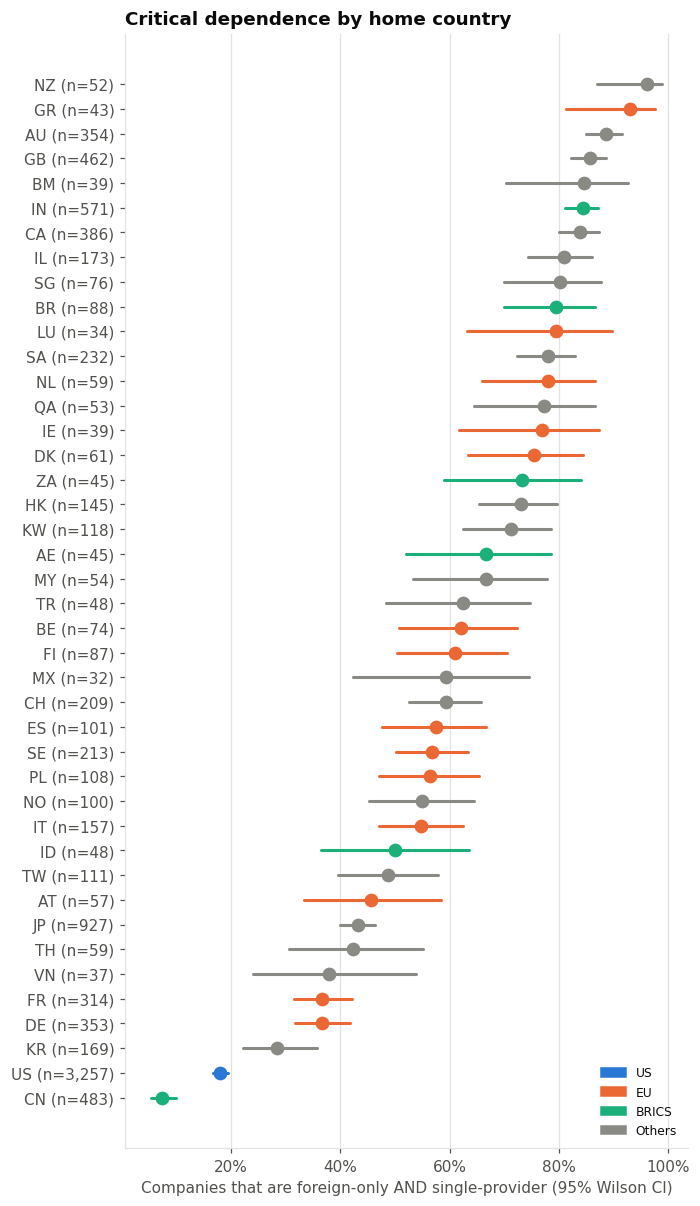

In [6]:
# "caso crítico": foreign-only E provedor único
comp["critical"] = np.where((comp["dependence_type"] == "foreign-only") & (comp["n_providers"] == 1), "critical", "other")
print(f"Casos críticos: {(comp['critical'] == 'critical').sum():,} de {len(comp):,} "
      f"({100 * (comp['critical'] == 'critical').mean():.1f}%) | "
      f"receita: {100 * comp.loc[comp['critical'] == 'critical', 'revenue_ttm'].sum() / comp['revenue_ttm'].sum():.1f}%")

crit_bloc = prop_ci_table(comp, "home_bloc", "critical", ["critical", "other"])
crit_bloc = crit_bloc[crit_bloc["critical"] == "critical"].set_index("home_bloc").reindex(BLOCS)
display(crit_bloc[["k", "n", "pct", "lo", "hi"]])
save_table(crit_bloc, "red_critical_by_bloc")

crit_cty = prop_ci_table(comp[comp["home"].map(comp["home"].value_counts()) >= MIN_N], "home", "critical", ["critical", "other"])
crit_cty = crit_cty[crit_cty["critical"] == "critical"].set_index("home").sort_values("pct", ascending=False)
save_table(crit_cty, "red_critical_by_country")

fig, ax = plt.subplots(figsize=(6.6, 0.28 * len(crit_cty) + 1.4))
ci_dots(ax, [f"{c} (n={n:,})" for c, n in zip(crit_cty.index, crit_cty["n"])], crit_cty["pct"],
        crit_cty["lo"], crit_cty["hi"], [BLOC_COLOR[bloc_of_country[c]] for c in crit_cty.index])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xlabel("Companies that are foreign-only AND single-provider (95% Wilson CI)")
ax.set_title("Critical dependence by home country")
ax.legend(handles=[Patch(color=BLOC_COLOR[b], label=b) for b in BLOCS], loc="lower right", fontsize=8)
save_fig(fig, "fig_red_critical_country")
plt.show()

## 3. Quem depende de provedor estrangeiro mantém uma alternativa doméstica?

5,649 empresas com ao menos um provedor estrangeiro (54.9% da amostra)


,k,n,pct,lo,hi,pct_revenue
home_bloc,,,,,,
US,20,650,3.08,2.00,4.70,19.68
EU,207,1236,16.75,14.77,18.93,20.80
BRICS,48,755,6.36,4.83,8.33,22.85
Others,243,3008,8.08,7.16,9.11,15.34


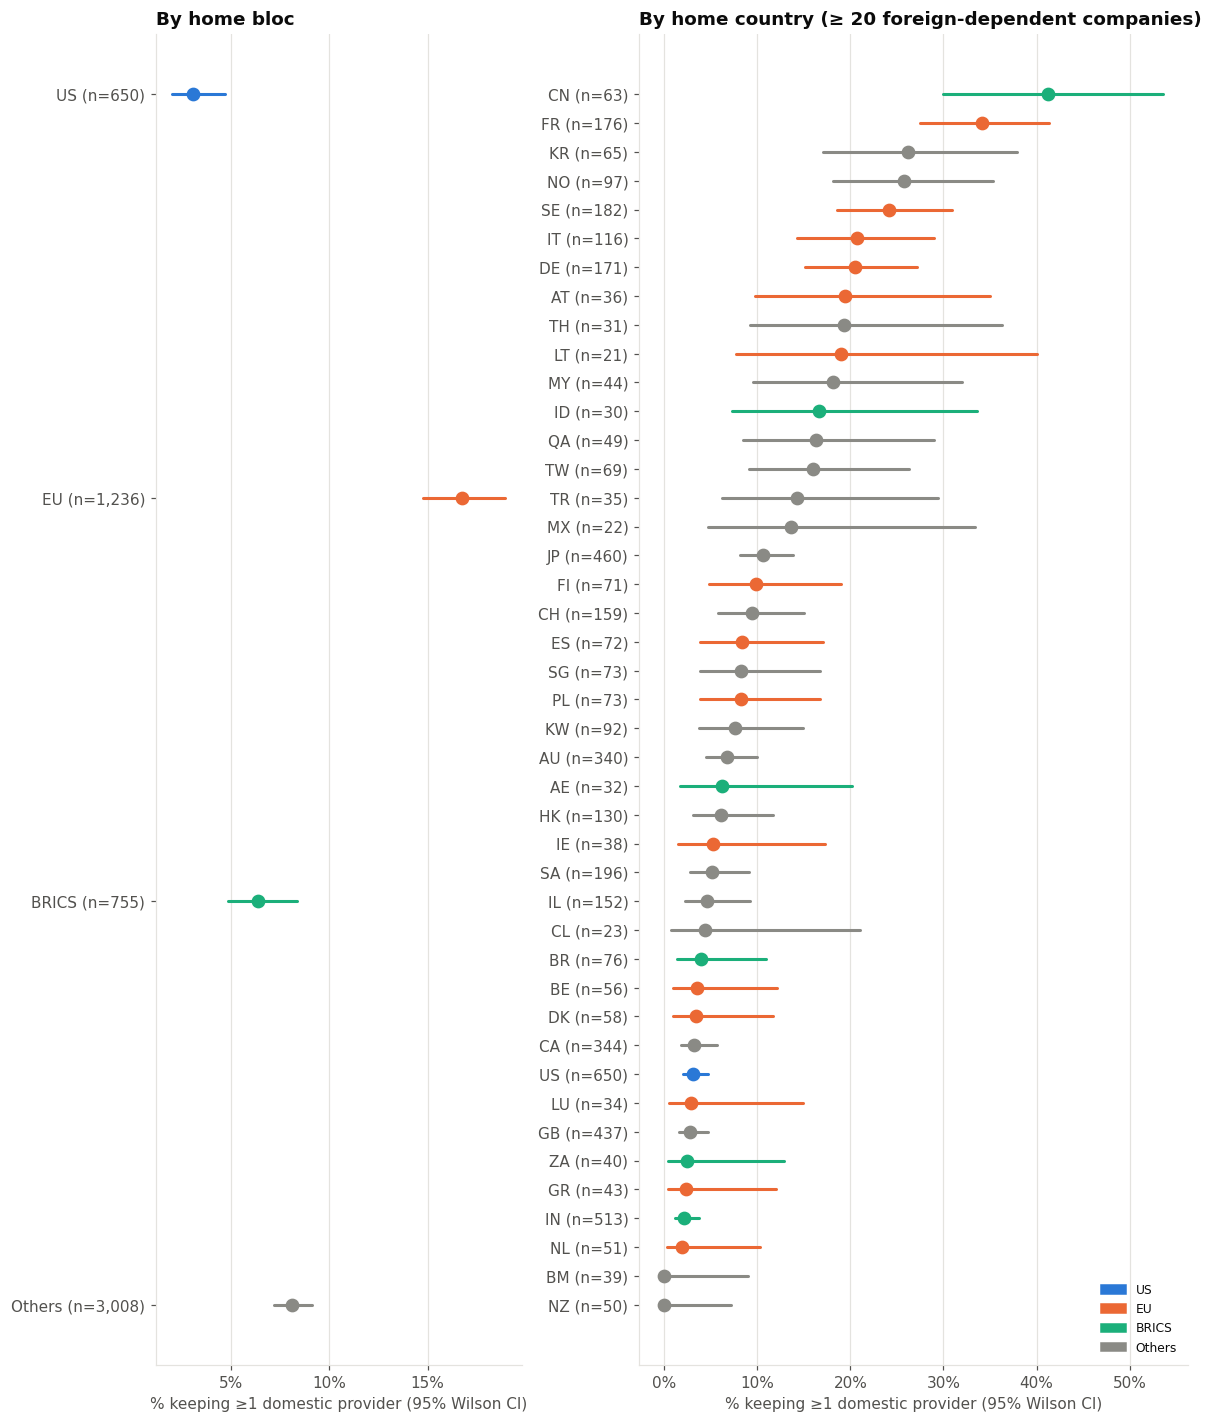

In [7]:
fd = comp[comp["has_foreign"]].copy()        # foreign-only + mixed
print(f"{len(fd):,} empresas com ao menos um provedor estrangeiro "
      f"({100 * len(fd) / len(comp):.1f}% da amostra)")
fd["alt"] = np.where(fd["has_domestic"], "has domestic alternative", "no domestic alternative")
ALT = ["has domestic alternative", "no domestic alternative"]

alt_bloc = prop_ci_table(fd, "home_bloc", "alt", ALT)
alt_bloc = alt_bloc[alt_bloc["alt"] == ALT[0]].set_index("home_bloc").reindex(BLOCS)
rev_alt = (fd.groupby(["home_bloc", "alt"])["revenue_ttm"].sum().unstack().reindex(BLOCS).fillna(0))
alt_bloc["pct_revenue"] = 100 * rev_alt[ALT[0]] / rev_alt.sum(axis=1)
display(alt_bloc[["k", "n", "pct", "lo", "hi", "pct_revenue"]])
save_table(alt_bloc, "red_domestic_alternative_by_bloc")

MIN_FD = 20   # n mínimo de empresas dependentes de estrangeiro por país
cnt_fd = fd["home"].value_counts()
alt_cty = prop_ci_table(fd[fd["home"].isin(cnt_fd[cnt_fd >= MIN_FD].index)], "home", "alt", ALT)
alt_cty = alt_cty[alt_cty["alt"] == ALT[0]].set_index("home").sort_values("pct", ascending=False)
save_table(alt_cty, "red_domestic_alternative_by_country")

fig, axes = plt.subplots(1, 2, figsize=(11, max(3.6, 0.28 * len(alt_cty) + 1)),
                         gridspec_kw={"width_ratios": [0.8, 1.2]})
ci_dots(axes[0], [f"{b} (n={int(n):,})" for b, n in zip(BLOCS, alt_bloc["n"])], alt_bloc["pct"],
        alt_bloc["lo"], alt_bloc["hi"], [BLOC_COLOR[b] for b in BLOCS])
axes[0].invert_yaxis()
axes[0].set_title("By home bloc")
ci_dots(axes[1], [f"{c} (n={n:,})" for c, n in zip(alt_cty.index, alt_cty["n"])], alt_cty["pct"],
        alt_cty["lo"], alt_cty["hi"], [BLOC_COLOR[bloc_of_country[c]] for c in alt_cty.index])
axes[1].invert_yaxis()
axes[1].set_title(f"By home country (≥ {MIN_FD} foreign-dependent companies)")
for ax in axes:
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.set_xlabel("% keeping ≥1 domestic provider (95% Wilson CI)")
axes[1].legend(handles=[Patch(color=BLOC_COLOR[b], label=b) for b in BLOCS], loc="lower right", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig_red_domestic_alternative")
plt.show()

## 4. Testes estatísticos

- **Correlação de Spearman** entre log(receita) e nº de provedores: empresas maiores são mais redundantes?
- **Kruskal–Wallis** do nº de provedores entre blocos.
- **Regressão logística** de `multi-provider` ($\ge 2$ provedores) sobre log$_{10}$(receita), bloco (ref.: US) e setor (razões de chance).

In [8]:
from scipy.stats import spearmanr, kruskal
import statsmodels.formula.api as smf

lr = np.log10(comp["revenue_ttm"].clip(lower=1))
rho, p = spearmanr(lr, comp["n_providers"])
print(f"Spearman (log10 receita x nº de provedores): rho = {rho:.3f}, p = {p:.2e}")
H, p = kruskal(*[comp.loc[comp["home_bloc"] == b, "n_providers"] for b in BLOCS])
print(f"Kruskal-Wallis (nº de provedores entre blocos): H = {H:.1f}, p = {p:.2e}")

reg = comp.assign(multi=(comp["n_providers"] >= 2).astype(int), log_rev=lr)
m = smf.logit("multi ~ log_rev + C(home_bloc, Treatment('US')) + C(sector)", data=reg).fit(disp=0)
or_tab = pd.DataFrame({"OR": np.exp(m.params), "CI_lo": np.exp(m.conf_int()[0]),
                       "CI_hi": np.exp(m.conf_int()[1]), "p": m.pvalues})
display(or_tab[or_tab.index.str.contains("log_rev|home_bloc")])
print(f"n = {int(m.nobs):,} | pseudo-R2 (McFadden) = {m.prsquared:.3f}")
save_table(or_tab, "red_logit_multi_provider")

Spearman (log10 receita x nº de provedores): rho = 0.126, p = 2.06e-37
Kruskal-Wallis (nº de provedores entre blocos): H = 347.9, p = 4.26e-75


,OR,CI_lo,CI_hi,p
"C(home_bloc, Treatment('US'))[T.BRICS]",3.47,2.84,4.23,0.00
"C(home_bloc, Treatment('US'))[T.EU]",4.65,3.88,5.58,0.00
"C(home_bloc, Treatment('US'))[T.Others]",2.26,1.91,2.68,0.00
log_rev,1.45,1.36,1.55,0.00


n = 10,274 | pseudo-R2 (McFadden) = 0.062


## 5. Sensibilidade

(i) definição do "provedor": grupo (baseline), organização sem de-para e domínio do NS; (ii) alternativa doméstica **sem de-para** e com **BRICS de 5 membros**.

In [9]:
n = len(comp)
single = {
    "Provider group (dp_as_org) — baseline": (v4.assign(k=v4["dp_as_org"]).groupby("rank")["k"].nunique() == 1).mean(),
    "Organization, no de-para (as_org)": (v4.groupby("rank")["as_org"].nunique() == 1).mean(),
    "NS domain (ns_apex)": (v4.groupby("rank")["ns_apex"].nunique() == 1).mean(),
    "ASN": (v4.groupby("rank")["asn"].nunique() == 1).mean(),
}
display(pd.Series({k: 100 * v for k, v in single.items()}, name="% single (SPOF)").to_frame())

cp_nd = company_provider(v4, "as_org", "as_country_code")
comp_nd = company_table(v4, cp_nd)
v4c = load_ipv4(brics=BRICS_CORE)
comp_c = company_table(v4c, company_provider(v4c, brics=BRICS_CORE))

def alt_share(df_):
    f = df_[df_["has_foreign"]]
    return (100 * f.groupby("home_bloc")["has_domestic"].mean()).reindex(BLOCS)

sens = pd.DataFrame({"Baseline": alt_share(comp), "No de-para": alt_share(comp_nd),
                     "BRICS = 5 original members": alt_share(comp_c)}).T
display(sens)
save_table(sens, "red_sensitivity_domestic_alternative")

,% single (SPOF)
Provider group (dp_as_org) — baseline,86.35
"Organization, no de-para (as_org)",82.89
NS domain (ns_apex),68.18
ASN,80.63


home_bloc,US,EU,BRICS,Others
Baseline,3.08,16.75,6.36,8.08
No de-para,6.69,23.17,21.67,8.98
BRICS = 5 original members,3.08,16.75,5.92,8.14


## 6. Como ler e reportar

- A métrica central é o **% de empresas com um único grupo provedor (SPOF)**, com o IC de Wilson; compare com o % que usa um único NS e um único ASN para mostrar o quanto a redundância "aparente" (vários NS) é menor ao nível de organização.
- O **quadrante crítico** (foreign-only + provedor único) resume o risco combinado de soberania e resiliência.
- A **alternativa doméstica** deve ser interpretada junto com a *disponibilidade* de provedores domésticos relevantes em cada país (um país sem provedor local competitivo não "escolhe" depender do estrangeiro).
- **Limitações:** a redundância é medida pelo DNS *autoritativo do domínio raiz declarado no cadastro de mercado*; não captura redundância na camada de hospedagem, em subdomínios nem em IPv6 (fora do escopo).